# Loan Portfolio Analysis (Prosper Marketplace, 2005-2014)

Built on the star schema and KPI tables produced by the Airflow DAG `lending_portfolio_pipeline`.

**Business question:** Where does the lending portfolio carry the most credit risk, and is that
risk priced correctly?

Each finding follows **problem → metric → insight → recommendation**.

**Measurement rule used throughout:** default rates use **matured loans only** (the loan's full term
has passed by the data snapshot, March 2014). Young loans have not had time to default, so
including them would make risk look lower than it really is.

In [1]:
from pathlib import Path
import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

DB = Path("../include/warehouse/lending.duckdb")
con = duckdb.connect(str(DB), read_only=True)
q = lambda sql: con.sql(sql).df()

# Chart style: one accent colour for single-series charts, recessive grid
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 10,
})
pct = mtick.PercentFormatter(1.0, decimals=0)
step5 = lambda: mtick.MultipleLocator(0.05)
CHARTS = Path("charts"); CHARTS.mkdir(exist_ok=True)

## 0. Portfolio at a glance

In [2]:
q('''
SELECT
    count(*)                                         AS loans,
    round(sum(loan_amount) / 1e6, 1)                 AS amount_originated_musd,
    count(DISTINCT b.member_key)                     AS borrowers,
    min(d.full_date)                                 AS first_loan,
    max(d.full_date)                                 AS last_loan,
    sum(is_matured::int)                             AS matured_loans,
    round(avg(CASE WHEN is_matured THEN is_default::int END), 4) AS matured_default_rate
FROM marts.fact_loan f
JOIN marts.dim_borrower b USING (borrower_sk)
JOIN marts.dim_date d ON f.origination_date_key = d.date_key
WHERE loan_status_group <> 'Cancelled'
''')

,loans,amount_originated_musd,borrowers,first_loan,last_loan,matured_loans,matured_default_rate
0,113061,940.1,90827,2005-11-15,2014-03-12,39212.0,0.3111


## 1. Origination volume: growth, and a 6-month gap

**Problem:** Is the business growing, and are there periods the trend analysis must treat with care?
**Metric:** monthly amount originated (`kpi.kpi_monthly_originations`).

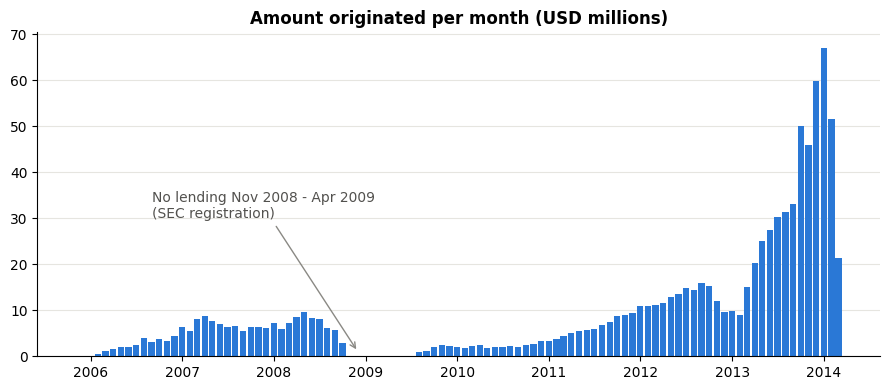

,year,loans,amount_musd
0,2005,22.0,0.1
1,2006,5902.0,28.1
2,2007,11460.0,80.8
3,2008,11551.0,69.6
4,2009,2047.0,8.9
5,2010,5652.0,26.9
6,2011,11228.0,75.1
7,2012,19553.0,153.2
8,2013,33912.0,357.4
9,2014,11734.0,140.0


In [3]:
m = q("SELECT month_start, amount_originated, weighted_avg_rate FROM kpi.kpi_monthly_originations")
fig, ax = plt.subplots()
ax.bar(m.month_start, m.amount_originated / 1e6, width=25, color=BLUE)
ax.set_title("Amount originated per month (USD millions)")
ax.annotate("No lending Nov 2008 - Apr 2009\n(SEC registration)", xy=(m.month_start[37], 1),
            xytext=(m.month_start[10], 30), arrowprops=dict(arrowstyle="->", color=GREY), color="#52514e")
fig.tight_layout(); fig.savefig(CHARTS / "01_monthly_originations.png", dpi=150); plt.show()

q('''SELECT year(month_start) AS year, sum(loans_originated) AS loans,
            round(sum(amount_originated)/1e6, 1) AS amount_musd
     FROM kpi.kpi_monthly_originations GROUP BY 1 ORDER BY 1''')

**Insight:** Volume grew from about USD 27M (2010) to about USD 357M (2013), roughly 13x in three years.
There were no originations between November 2008 and April 2009. The KPI table builds months from a
date spine, so this gap appears as zeros rather than being silently skipped by `LAG()`.

**Recommendation:** Treat 2009 as a structural break. Report pre-2009 and post-2009 performance
separately, and never compute growth rates across the gap.

## 2. Vintage analysis: underwriting improved sharply after the 2009 relaunch

**Problem:** Did credit quality change over time?
**Metric:** default rate and net loss rate of **matured 36-month vintages** (`kpi.kpi_vintage_default`).

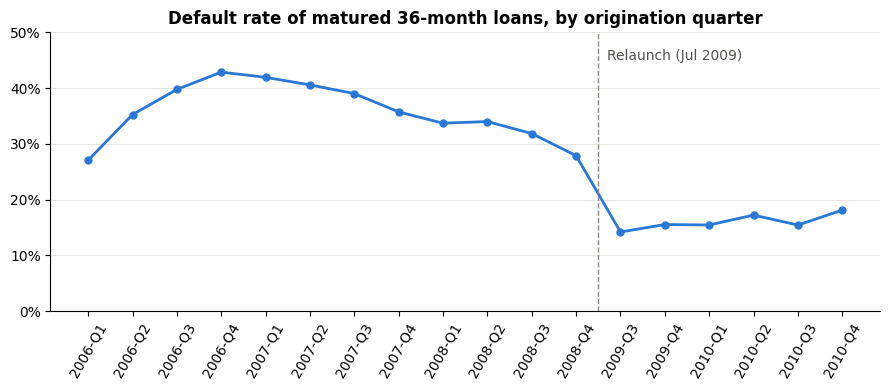

,vintage,default_rate,net_loss_rate,loans
0,2006-Q1,0.270701,0.170726,314.0
1,2006-Q2,0.352518,0.241081,1251.0
2,2006-Q3,0.397622,0.260239,1934.0
3,2006-Q4,0.428631,0.274705,2403.0
4,2007-Q1,0.419292,0.299481,3079.0
5,2007-Q2,0.405709,0.298951,3118.0
6,2007-Q3,0.390116,0.274952,2671.0
7,2007-Q4,0.357253,0.263518,2592.0
8,2008-Q1,0.337020,0.241332,3074.0
9,2008-Q2,0.340009,0.236970,4344.0


In [4]:
v = q('''
SELECT vintage,
       sum(defaulted_loans) / sum(loans)                          AS default_rate,
       sum(net_loss_rate * amount_originated) / sum(amount_originated) AS net_loss_rate,
       sum(loans) AS loans
FROM kpi.kpi_vintage_default
GROUP BY vintage
HAVING bool_and(is_matured) AND sum(loans) >= 300
ORDER BY vintage
''')
fig, ax = plt.subplots()
ax.plot(v.vintage, v.default_rate, color=BLUE, linewidth=2, marker="o", markersize=5)
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, 0.5)
ax.set_title("Default rate of matured 36-month loans, by origination quarter")
ax.tick_params(axis="x", rotation=60)
i = list(v.vintage).index("2009-Q3")
ax.axvline(i - 0.5, color=GREY, linestyle="--", linewidth=1)
ax.text(i - 0.3, 0.45, "Relaunch (Jul 2009)", color="#52514e")
fig.tight_layout(); fig.savefig(CHARTS / "02_vintage_default.png", dpi=150); plt.show()
v

**Insight:** Matured vintages from 2006-Q2 to 2008-Q3 defaulted at 32-43%. Vintages from 2009-Q3
to 2010-Q4 defaulted at 14-18%. Net loss rates fell from 21-30% of principal to 7-11%.

**Recommendation:** Track every new vintage against the 2009-2010 baseline at the same loan age, and
alert when a vintage drifts above it. This is a monthly vintage curve report that the DAG can refresh automatically.

## 3. Risk vs return by grade: is risk priced correctly?

**Problem:** Higher-risk grades default more. Does the extra interest cover the extra losses?
**Metric:** default rate and net return on principal = (interest & fees - net principal loss) / amount lent,
for matured post-2009 loans (`kpi.kpi_grade_risk_return`).

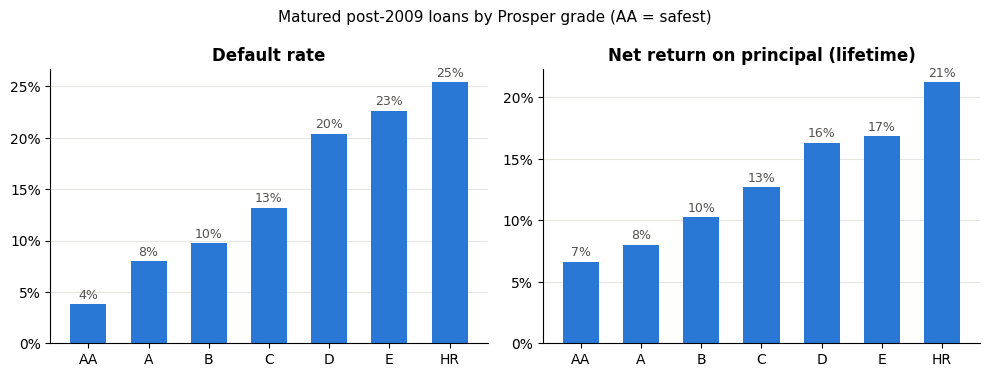

,grade_code,grade_rank,risk_band,matured_loans,amount_lent,avg_borrower_rate,default_rate,net_loss_rate,net_return_on_principal,return_rank,risk_rank
0,AA,1,Prime,1178,7867219.0,0.0785,0.0382,0.0308,0.0664,7,7
1,A,2,Prime,1767,9817544.0,0.0991,0.0798,0.0416,0.0803,6,6
2,B,3,Near-prime,1067,7159153.0,0.1383,0.0975,0.0564,0.1025,5,5
3,C,4,Near-prime,1320,5883723.0,0.1935,0.1318,0.0860,0.1269,4,4
4,D,5,Subprime,2362,9912965.0,0.2567,0.2041,0.1341,0.1630,3,3
5,E,6,Subprime,1289,4661470.0,0.3044,0.2265,0.1608,0.1682,2,2
6,HR,7,High risk,1150,3518921.0,0.3241,0.2539,0.1792,0.2121,1,1


In [5]:
g = q("SELECT * FROM kpi.kpi_grade_risk_return ORDER BY grade_rank")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True)
for ax, col, title in [(axes[0], "default_rate", "Default rate"),
                       (axes[1], "net_return_on_principal", "Net return on principal (lifetime)")]:
    bars = ax.bar(g.grade_code, g[col], color=BLUE, width=0.6)
    ax.bar_label(bars, labels=[f"{x:.0%}" for x in g[col]], padding=2, fontsize=9, color="#52514e")
    ax.yaxis.set_major_formatter(pct); ax.yaxis.set_major_locator(step5()); ax.set_title(title)
fig.suptitle("Matured post-2009 loans by Prosper grade (AA = safest)", fontsize=11)
fig.tight_layout(); fig.savefig(CHARTS / "03_grade_risk_return.png", dpi=150); plt.show()
g

**Insight:** Default rates rise steadily from 3.8% (AA) to 25.4% (HR), so the grading model ranks risk
correctly. Pricing rises faster than losses: lifetime net return on principal grows from 6.6% (AA)
to 21.2% (HR). Caveat: the matured post-2009 sample covers only about 10k loans originated mid-2009
to early 2011, a benign credit period.

**Recommendation:** Higher grades are not under-priced on this evidence. Before growing high-risk
volume, re-test the result on the 2011-2012 vintages once they mature, because returns in the riskiest
grades are the most sensitive to a downturn.

## 4. Repeat borrowers default far less, but pay almost the same rate

**Problem:** Does a borrower's history on the platform carry risk information that the grade misses?
**Metric:** default rate of matured post-2009 loans, first loan vs repeat loan, **within the same grade**
(`kpi.kpi_borrower_segments`). Comparing within grade and era removes the two biggest confounders.

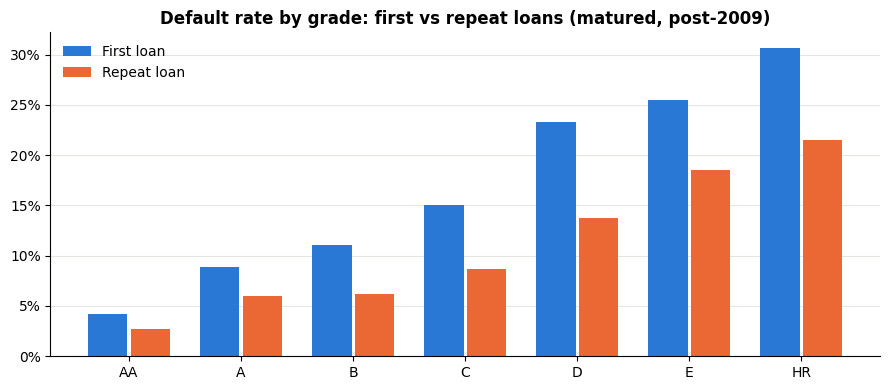

,borrower_type,matured_loans,default_rate,avg_borrower_rate
0,Repeat loan,3434.0,0.1252,0.1915
1,First loan,6699.0,0.1642,0.1978


In [6]:
r = q('''
SELECT grade_code, borrower_type,
       sum(matured_defaults) / sum(matured_loans) AS default_rate,
       sum(avg_borrower_rate * loans) / sum(loans) AS avg_rate,
       sum(matured_loans) AS matured_loans
FROM kpi.kpi_borrower_segments
WHERE lending_era = 'Post-2009'
GROUP BY ALL
''')
order = ["AA", "A", "B", "C", "D", "E", "HR"]
piv = r.pivot(index="grade_code", columns="borrower_type", values="default_rate").loc[order]
x = range(len(order)); w = 0.38
fig, ax = plt.subplots()
b1 = ax.bar([i - w/2 for i in x], piv["First loan"], w - 0.03, color=BLUE, label="First loan")
b2 = ax.bar([i + w/2 for i in x], piv["Repeat loan"], w - 0.03, color=ORANGE, label="Repeat loan")
ax.set_xticks(list(x), order); ax.yaxis.set_major_formatter(pct); ax.yaxis.set_major_locator(step5())
ax.set_title("Default rate by grade: first vs repeat loans (matured, post-2009)")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(CHARTS / "04_repeat_borrowers.png", dpi=150); plt.show()

q('''
SELECT borrower_type,
       sum(matured_loans) AS matured_loans,
       round(sum(matured_defaults) / sum(matured_loans), 4) AS default_rate,
       round(sum(avg_borrower_rate * loans) / sum(loans), 4) AS avg_borrower_rate
FROM kpi.kpi_borrower_segments WHERE lending_era = 'Post-2009' GROUP BY 1
''')

**Insight:** In every grade, repeat borrowers default less than first-time borrowers: about 40% less
in grades B, C and D (for example, D is 13.7% vs 23.3%). Yet they pay almost the same rate
(19.2% vs 19.8%), so the grade does not fully credit a good repayment history on the platform.
Note that the overall gap looks smaller (12.5% vs 16.4%) because repeat loans lean toward riskier
grades. Comparing within each grade removes that mix effect (Simpson's paradox).

**Recommendation:** Add "prior on-time Prosper loans" as a pricing factor, or offer rate discounts to
repeat borrowers in good standing. This keeps low-risk customers who may otherwise refinance elsewhere.
Validate with an A/B pricing test before rollout.

## 5. Income at application is a strong risk signal

**Problem:** Which borrower profiles carry the most risk?
**Metric:** matured default rate by income range **at the time of the loan** (point-in-time from the SCD2
borrower dimension), post-2009.

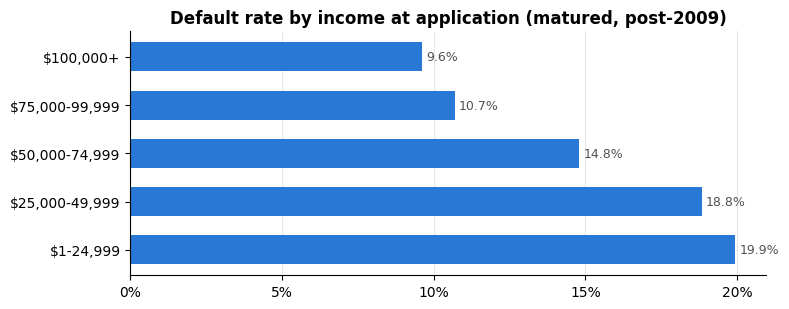

,income_range,default_rate,matured_loans
0,"$100,000+",0.096116,1519.0
1,"$75,000-99,999",0.106968,1636.0
2,"$50,000-74,999",0.147996,2919.0
3,"$25,000-49,999",0.188419,3195.0
4,"$1-24,999",0.199465,747.0


In [7]:
inc = q('''
SELECT income_range,
       sum(matured_defaults) / sum(matured_loans) AS default_rate,
       sum(matured_loans) AS matured_loans
FROM kpi.kpi_borrower_segments
WHERE lending_era = 'Post-2009'
GROUP BY 1 HAVING sum(matured_loans) >= 200
ORDER BY default_rate
''')
fig, ax = plt.subplots(figsize=(8, 3.2))
bars = ax.barh(inc.income_range, inc.default_rate, color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{x:.1%}" for x in inc.default_rate], padding=3, fontsize=9, color="#52514e")
ax.xaxis.set_major_formatter(pct); ax.xaxis.set_major_locator(step5()); ax.grid(axis="x"); ax.grid(axis="y", visible=False); ax.invert_yaxis()
ax.set_title("Default rate by income at application (matured, post-2009)")
fig.tight_layout(); fig.savefig(CHARTS / "05_income_risk.png", dpi=150); plt.show()
inc

**Insight:** Borrowers earning USD 100k+ defaulted at 9.6%, about half the rate of the USD 25k-49k band (18.8%).
The gradient is smooth across every band, so income adds signal on top of the grade.

**Recommendation:** Keep verified income as a hard input to pricing and limits. For the lowest bands,
consider smaller maximum loan sizes rather than outright decline, to retain volume while capping loss severity.

## Data-quality notes found while building the pipeline
- **871 duplicate loan rows** in the source differ only in `ProsperScore`. Staging keeps the lowest
  (most conservative) score, and a check confirms staging rows = distinct source listings.
- **2 loans** report a net principal loss a few cents above the loan amount (rounding in the source).
  This is logged as a *warning* rather than a failure, so it is visible without blocking the daily refresh.
- **Two rating systems:** pre-2009 `CreditGrade` and post-2009 `ProsperRating` are unified into one
  `grade_code`, but grade-level comparisons use only one system so the letters mean the same thing.

In [8]:
q("SELECT check_name, severity, failed_rows, status FROM audit.dq_results "
  "WHERE run_at = (SELECT max(run_at) FROM audit.dq_results) ORDER BY status DESC, check_name")

,check_name,severity,failed_rows,status
0,loss_not_greater_than_loan_amount,warn,2,WARN
1,default_has_closed_date,warn,0,PASS
2,dim_borrower_sk_unique,error,0,PASS
3,fact_keys_not_null,error,0,PASS
4,fact_loan_key_unique,error,0,PASS
5,fact_row_count_matches_staging,error,0,PASS
6,fk_fact_to_dim_borrower,error,0,PASS
7,fk_fact_to_dim_credit_grade,error,0,PASS
8,fk_fact_to_dim_date,error,0,PASS
9,fk_fact_to_dim_geography,error,0,PASS
